# Scale-Invariant Feature Transform (SIFT) From Scratch (NumPy Only)
**Objective:** Implement the four stages of Lowe's **SIFT (Scale-Invariant Feature Transform)** algorithm purely in **NumPy**:
1. **Scale-Space Extrema Detection:** Construct a Gaussian scale-space pyramid and compute **Difference-of-Gaussians (DoG)** images to locate $3 \times 3 \times 3$ local extrema across space and scale.
2. **Keypoint Localization & Edge Elimination:** Filter out low-contrast keypoints ($|D(\mathbf{x})| < T_c$) and eliminate unstable edge responses using the $2 \times 2$ Hessian curvature ratio:
   $$\frac{\text{Tr}(\mathbf{H})^2}{\text{Det}(\mathbf{H})} < \frac{(r + 1)^2}{r}, \quad (r = 10)$$
3. **Orientation Assignment:** Compute a $36$-bin gradient orientation histogram ($10^\circ$ per bin) weighted by a Gaussian window ($\sigma = 1.5 \sigma_{\text{scale}}$) to achieve **rotation invariance**.
4. **128-D Keypoint Descriptor Generation:** Rotate a $16 \times 16$ neighborhood relative to the dominant orientation, divide into $4 \times 4$ sub-blocks of $8$ orientation bins ($4 \times 4 \times 8 = 128$ dimensions), and apply clipped L2 normalization ($\le 0.2$) for **illumination invariance**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a 160x160 test image with corners, circles, and multi-scale blocks
N = 160
yy, xx = np.indices((N, N))
img = np.zeros((N, N), dtype=np.float32)

# Sharp geometric structures at different scales
img[20:60, 20:60] = 0.85                                   # Large square
img[30:50, 30:50] = 0.25                                   # Inner square
img[((yy - 45)**2 + (xx - 115)**2) <= 22**2] = 0.9         # Large circle
img[((yy - 45)**2 + (xx - 115)**2) <= 9**2] = 0.2          # Concentric inner circle
img[85:135, 35:95] = 0.75                                  # Rectangle
img[95:110, 45:60] = 1.0                                   # Bright corner patch
img[105:135, 110:140] = 0.8                                # Bottom-right square
for k in range(18):
    img[105 + k, 110 : 110 + (18 - k)] = 0.1               # Diagonal triangle cut


# 2. Pure NumPy Separable 2D Gaussian Blur
def gaussian_blur_numpy(image: np.ndarray, sigma: float) -> np.ndarray:
    radius = max(1, int(np.ceil(3.0 * sigma)))
    x = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-(x ** 2) / (2.0 * sigma ** 2))
    kernel /= np.sum(kernel)

    # Separable 1D convolutions (horizontal then vertical)
    pad_h = np.pad(image, ((0, 0), (radius, radius)), mode="reflect")
    win_h = np.lib.stride_tricks.sliding_window_view(pad_h, len(kernel), axis=1)
    blur_h = np.einsum("ijk,k->ij", win_h, kernel)

    pad_v = np.pad(blur_h, ((radius, radius), (0, 0)), mode="reflect")
    win_v = np.lib.stride_tricks.sliding_window_view(pad_v, len(kernel), axis=0)
    blur_v = np.einsum("ijk,k->ij", win_v, kernel)
    return blur_v


# 3. Full SIFT Pipeline in Pure NumPy (Single Octave Multi-Scale Pyramid)
def extract_sift_numpy(
    image: np.ndarray,
    num_intervals: int = 3,
    sigma0: float = 1.6,
    contrast_thresh: float = 0.03,
    edge_ratio: float = 10.0,
):
    """
    Extracts SIFT keypoints (y, x, scale, angle) and 128-D descriptors using pure NumPy.
    """
    # Step 1: Build Gaussian Scale Space (s + 3 blurred images -> s + 2 DoG images)
    num_scales = num_intervals + 3
    k = 2.0 ** (1.0 / num_intervals)
    sigmas = [sigma0 * (k ** i) for i in range(num_scales)]

    gauss_pyr = [gaussian_blur_numpy(image, s) for s in sigmas]
    dog_pyr = np.stack([gauss_pyr[i + 1] - gauss_pyr[i] for i in range(num_scales - 1)], axis=0)

    # Step 2: Detect 3x3x3 Scale-Space Extrema + Contrast & Hessian Edge Filtering
    keypoints = []
    r_thresh = ((edge_ratio + 1.0) ** 2) / edge_ratio
    border = 16  # Margin to safely extract 16x16 descriptor patch

    for s_idx in range(1, dog_pyr.shape[0] - 1):
        prev_dog = dog_pyr[s_idx - 1]
        curr_dog = dog_pyr[s_idx]
        next_dog = dog_pyr[s_idx + 1]
        scale_sigma = sigmas[s_idx]

        # Precompute gradients & Hessian components on current DoG slice
        dxx = curr_dog[1:-1, 2:] + curr_dog[1:-1, :-2] - 2.0 * curr_dog[1:-1, 1:-1]
        dyy = curr_dog[2:, 1:-1] + curr_dog[:-2, 1:-1] - 2.0 * curr_dog[1:-1, 1:-1]
        dxy = 0.25 * (
            curr_dog[2:, 2:] - curr_dog[2:, :-2] - curr_dog[:-2, 2:] + curr_dog[:-2, :-2]
        )

        for y in range(border, image.shape[0] - border):
            for x in range(border, image.shape[1] - border):
                val = curr_dog[y, x]
                if abs(val) < contrast_thresh:
                    continue

                # 3x3x3 neighborhood check
                patch_prev = prev_dog[y - 1 : y + 2, x - 1 : x + 2]
                patch_curr = curr_dog[y - 1 : y + 2, x - 1 : x + 2]
                patch_next = next_dog[y - 1 : y + 2, x - 1 : x + 2]
                cube = np.stack([patch_prev, patch_curr, patch_next], axis=0)

                if val != np.max(cube) and val != np.min(cube):
                    continue

                # Hessian Principal Curvature Edge Check
                h_xx = dxx[y - 1, x - 1]
                h_yy = dyy[y - 1, x - 1]
                h_xy = dxy[y - 1, x - 1]
                trace = h_xx + h_yy
                det = h_xx * h_yy - (h_xy ** 2)
                if det <= 1e-12 or (trace ** 2) / det >= r_thresh:
                    continue

                # Step 3: Canonical Orientation Assignment (36 bins, 10 deg/bin)
                g_img = gauss_pyr[s_idx]
                win_r = int(round(3.0 * 1.5 * scale_sigma))
                y0, y1 = max(1, y - win_r), min(image.shape[0] - 1, y + win_r + 1)
                x0, x1 = max(1, x - win_r), min(image.shape[1] - 1, x + win_r + 1)

                yy_w, xx_w = np.meshgrid(np.arange(y0, y1), np.arange(x0, x1), indexing="ij")
                gx = 0.5 * (g_img[yy_w, xx_w + 1] - g_img[yy_w, xx_w - 1])
                gy = 0.5 * (g_img[yy_w + 1, xx_w] - g_img[yy_w - 1, xx_w])

                mag = np.sqrt(gx ** 2 + gy ** 2)
                ang = np.rad2deg(np.arctan2(gy, gx)) % 360.0
                weight = np.exp(-((yy_w - y) ** 2 + (xx_w - x) ** 2) / (2.0 * (1.5 * scale_sigma) ** 2))

                ori_hist, _ = np.histogram(ang.ravel(), bins=36, range=(0.0, 360.0), weights=(mag * weight).ravel())
                dominant_bin = int(np.argmax(ori_hist))
                dominant_angle = (dominant_bin + 0.5) * 10.0

                # Step 4: 128-D Rotation-Invariant Descriptor (4x4 subregions x 8 bins)
                theta_rad = np.deg2rad(dominant_angle)
                cos_t, sin_t = np.cos(theta_rad), np.sin(theta_rad)

                # Sample 16x16 rotated grid around keypoint
                grid_coords = np.linspace(-7.5, 7.5, 16)
                gy_grid, gx_grid = np.meshgrid(grid_coords, grid_coords, indexing="ij")
                rot_x = np.clip(np.round(x + cos_t * gx_grid - sin_t * gy_grid).astype(int), 1, image.shape[1] - 2)
                rot_y = np.clip(np.round(y + sin_t * gx_grid + cos_t * gy_grid).astype(int), 1, image.shape[0] - 2)

                dgx = 0.5 * (g_img[rot_y, rot_x + 1] - g_img[rot_y, rot_x - 1])
                dgy = 0.5 * (g_img[rot_y + 1, rot_x] - g_img[rot_y - 1, rot_x])
                dmag = np.sqrt(dgx ** 2 + dgy ** 2)
                dang = (np.rad2deg(np.arctan2(dgy, dgx)) - dominant_angle) % 360.0

                # Gaussian spatial weighting across 16x16 descriptor window
                desc_weight = np.exp(-(gx_grid ** 2 + gy_grid ** 2) / (2.0 * 8.0 ** 2))
                w_mag = dmag * desc_weight

                desc = np.zeros((4, 4, 8), dtype=np.float32)
                for row_blk in range(4):
                    for col_blk in range(4):
                        sub_ang = dang[row_blk * 4 : (row_blk + 1) * 4, col_blk * 4 : (col_blk + 1) * 4]
                        sub_mag = w_mag[row_blk * 4 : (row_blk + 1) * 4, col_blk * 4 : (col_blk + 1) * 4]
                        hist8, _ = np.histogram(sub_ang.ravel(), bins=8, range=(0.0, 360.0), weights=sub_mag.ravel())
                        desc[row_blk, col_blk] = hist8

                # Normalize, clip at 0.2 (non-linear illumination invariance), re-normalize
                vec = desc.ravel()
                vec /= (np.linalg.norm(vec) + 1e-8)
                vec = np.clip(vec, 0.0, 0.2)
                vec /= (np.linalg.norm(vec) + 1e-8)

                keypoints.append((y, x, scale_sigma, dominant_angle))
                if len(keypoints) == 1:
                    descriptors = [vec]
                else:
                    descriptors.append(vec)

    desc_array = np.array(descriptors, dtype=np.float32) if keypoints else np.empty((0, 128), dtype=np.float32)
    return keypoints, desc_array, dog_pyr


# Execute SIFT Keypoint Detection & Descriptor Extraction
keypoints, descriptors, dog_pyramid = extract_sift_numpy(img)

print(f"Detected SIFT Keypoints : {len(keypoints)}")
print(f"Descriptor Matrix Shape : {descriptors.shape} (N_keypoints x 128)")
if len(keypoints) > 0:
    print(f"Sample Keypoint 0       : y={keypoints[0][0]}, x={keypoints[0][1]}, σ={keypoints[0][2]:.2f}, θ={keypoints[0][3]:.1f}°")

Detected SIFT Keypoints : 17
Descriptor Matrix Shape : (17, 128) (N_keypoints x 128)
Sample Keypoint 0       : y=22, x=22, σ=2.02, θ=5.0°


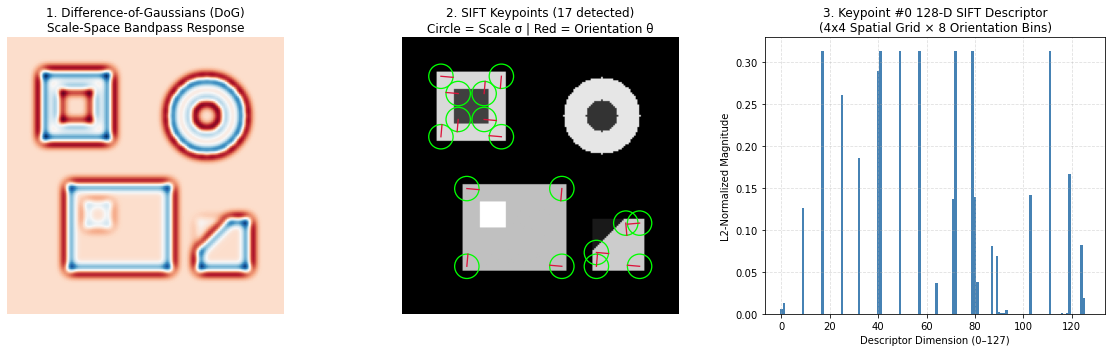

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Difference-of-Gaussians (DoG) Scale Response
axes[0].imshow(dog_pyramid[1], cmap="RdBu_r")
axes[0].set_title("1. Difference-of-Gaussians (DoG)\nScale-Space Bandpass Response")
axes[0].axis("off")

# Panel 2: Detected SIFT Keypoints with Scale Circles & Orientation Vectors
axes[1].imshow(img, cmap="gray", vmin=0, vmax=1)
for (ky, kx, kscale, kang) in keypoints:
    radius = kscale * 3.5
    circle = plt.Circle((kx, ky), radius, color="lime", fill=False, linewidth=1.3)
    axes[1].add_patch(circle)
    dx = radius * np.cos(np.deg2rad(kang))
    dy = radius * np.sin(np.deg2rad(kang))
    axes[1].plot([kx, kx + dx], [ky, ky + dy], color="crimson", linewidth=1.3)
axes[1].set_title(f"2. SIFT Keypoints ({len(keypoints)} detected)\nCircle = Scale σ | Red = Orientation θ")
axes[1].axis("off")

# Panel 3: 128-D SIFT Descriptor Vector of First Keypoint
if len(descriptors) > 0:
    axes[2].bar(np.arange(128), descriptors[0], width=1.0, color="steelblue")
    axes[2].set_title("3. Keypoint #0 128-D SIFT Descriptor\n(4x4 Spatial Grid × 8 Orientation Bins)")
    axes[2].set_xlabel("Descriptor Dimension (0–127)")
    axes[2].set_ylabel("L2-Normalized Magnitude")
    axes[2].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()